# Fitting a nerve pulse

In this tutorial, we stimulate one end of an excitable cable, such as a nerve fibre, and record the travelling pulse with four noisy electrodes. We fit three parameters of the [FitzHugh (1961)](https://doi.org/10.1016/S0006-3495(61)86902-6) and [Nagumo et al. (1962)](https://doi.org/10.1109/JRPROC.1962.288235) model, a simplified model of a nerve cell's electrical response, to these recordings. We then compute the uncertainty of the fitted values ([statistical estimation](../overview/inference/statistical-estimation.md)) and check their [identifiability](../overview/inference/identifiability.md). Since the true values are FitzHugh's own, the check is whether they fall inside the reported uncertainty.

## Setup

We import diff-soup in JAX float64 (double-precision) mode. The number of cells on the cable is the only setting that differs between CPU and GPU.

In [1]:
import time

import diff_soup as ds
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from diff_soup.domains import cartesian_grid_1d

jax.config.update("jax_enable_x64", True)
GPU = jax.default_backend() == "gpu"
N = 200 if GPU else 100              # cells on the cable
print(f"diff-soup {ds.__version__}, JAX {jax.__version__}, {jax.devices()[0]}")

diff-soup 1.1.0, JAX 0.11.2, cuda:0


## The problem

We consider the membrane voltage $v(x, t)$ and a slow recovery variable $w(x, t)$ that returns the membrane to rest, which obey

$$
\frac{\partial v}{\partial t} = \frac{\partial^2 v}{\partial x^2} + v - \frac{v^3}{3} - w, \qquad
\frac{\partial w}{\partial t} = \varepsilon\,(v + a - b\,w),
$$

on $0 < x < 100$ with zero flux through both ends, where $a$, $b$ and $\varepsilon$ are the parameters we fit. The cable starts at the uniform rest state for the true parameters, $v_r = -1.199$ and $w_r = -0.624$, except for $v = 1$ on $x < 5$.

The true values are $a = 0.7$, $b = 0.8$ and $\varepsilon = 0.08$, and we compute the rest state from them first. Probes at $x = 20$, 40, 60 and 80 record $v$ once per time unit up to $t = 110$, with Gaussian noise of standard deviation $\sigma = 0.05$.

In [2]:
TRUE = {"a": 0.7, "b": 0.8, "eps": 0.08}
START = {"a": 0.5, "b": 1.0, "eps": 0.12}

def rest_state(a, b):
    """The resting (v, w): the real root of v - v**3/3 = (v + a)/b."""
    roots = np.roots([-1 / 3, 0.0, 1 - 1 / b, -a / b])
    v = roots[np.isreal(roots)].real[0]
    return v, (v + a) / b

v_r, w_r = rest_state(TRUE["a"], TRUE["b"])
print(f"v_r = {v_r:.4f}, w_r = {w_r:.4f}")

v_r = -1.1994, w_r = -0.6243


## Build the model

We declare $v$ and $w$ as differential fields on a grid of the cable, and $a$, $b$ and $\varepsilon$ as learnable parameters with bounds and a log-normal prior. The fit starts from $a = 0.5$, $b = 1.0$ and $\varepsilon = 0.12$. We centre each `ds.inference.LogNormalPrior` on its starting value with `log_sd=1.0`, which says the start is good to a factor of about $e$.

In [3]:
grid = cartesian_grid_1d(N, 0.0, 100.0)

spec = ds.problem("fitzhugh_nagumo")
spec.domain("cable", grid)
spec.field("v", mass="differential", scale=1.0, init=lambda x: jnp.where(x < 5.0, 1.0, v_r))
spec.field("w", mass="differential", scale=1.0, init=lambda x: jnp.full_like(x, w_r))
params = {name: spec.param(name, value=value, learnable=True, bounds=(0.01, 2.0),
                           prior=ds.inference.LogNormalPrior(median=value, log_sd=1.0))
          for name, value in START.items()}

Next, we write the two equations and declare with `spec.observe.field` what the electrodes read, $v$ at the four probe cells. The fit refers to this observation by name in its measurement ([observables](../overview/inference/fitting.md#observables)).

In [4]:
@spec.equation(writes="v", reads=("v", "w"))
def voltage(q):
    return q.ops.laplacian(q.v) + q.v - q.v**3 / 3 - q.w

@spec.equation(writes="w", reads=("v", "w"))
def recovery(q):
    return q.p.eps * (q.v + q.p.a - q.p.b * q.w)

x = np.asarray(grid.nodes).ravel()
cells = np.searchsorted(x, [20.0, 40.0, 60.0, 80.0])
spec.observe.field(name="probes", fn=lambda q: q.v[cells])

problem = spec.build()
y0 = spec.assemble_state({})

To make the data, we solve at the true parameters and add noise to $v$ at the probe cells, using `problem.field_slice("v")` to pick $v$ out of the flat state.

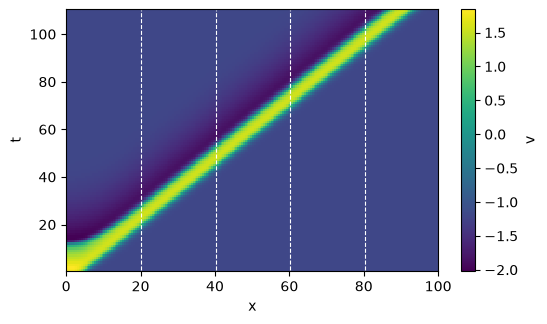

In [5]:
solver = ds.JIDA()
T = 110.0
ts = np.arange(1.0, T + 0.5, 1.0)

theta_true = ds.default_theta(problem, {params[k]: value for k, value in TRUE.items()})
sol = ds.pdesolve(problem, solver, (0.0, T), y0, theta=theta_true, saveat=ds.SaveAt(ts=ts))
sigma = 0.05
v = sol.ys[:, problem.field_slice("v")]
data = v[:, cells] + sigma * np.random.default_rng(0).standard_normal((ts.size, cells.size))

fig, ax = plt.subplots(figsize=(6, 3.4))
im = ax.pcolormesh(x, ts, v, cmap="viridis", shading="auto")
ax.vlines(x[cells], ts[0], ts[-1], colors="w", lw=0.8, linestyles="--")
ax.set_xlabel("x")
ax.set_ylabel("t")
fig.colorbar(im, ax=ax, label="v")
plt.show()

The pulse crosses the cable at a constant speed, and each probe (dashed) sees one spike.

## The fit

The likelihood `ds.inference.Gaussian` models each recorded value as the model's $v$ at that probe plus independent Gaussian noise of standard deviation $\sigma$. The objective `ds.inference.MAP()` adds the priors, so the fit returns the maximum a posteriori (MAP) estimate, which we compute with `ds.inference.NewtonTrustRegion`.

In [6]:
measurement = ds.inference.Measurement("v", ts, data, likelihood=ds.inference.Gaussian(sigma=sigma),
                                       observe="probes")
experiment = ds.inference.Experiment(problem, solver, (0.0, T), y0, (measurement,))
est = ds.inference.InferenceProblem(experiment, parameters=tuple(params.values()),
                                    objective=ds.inference.MAP())

t0 = time.perf_counter()
fit = ds.inference.optsolve(est, ds.inference.NewtonTrustRegion())
print(f"{fit.status.name} after {fit.n_steps} steps, {time.perf_counter() - t0:.1f} s")
print({name: round(float(fit[h]), 4) for name, h in params.items()})

COST_TOL after 15 steps, 20.9 s
{'a': 0.7008, 'b': 0.7991, 'eps': 0.0799}


The fit recovers all three parameters to within 0.001 of the truth in 15 steps. By default, `ds.inference.NewtonTrustRegion()` steps on the Gauss-Newton matrix, and `hessian="true"` steps on the exact Hessian instead.

## Goodness of fit

Before we trust any uncertainty, we check the noise model. `ds.inference.residual_report` divides each residual by its $\sigma$, so the standardized residuals should have mean zero, standard deviation one and no correlation in time.

In [7]:
channel = ds.inference.residual_report(est, fit).channels["v"]
print(f"mean {channel.mean:+.3f}, std {channel.std:.3f}, lag-1 autocorrelation {channel.lag1_autocorrelation:+.3f}")

mean -0.023, std 1.005, lag-1 autocorrelation -0.041


A mean of $-0.023$, a standard deviation of 1.005 and a lag-1 autocorrelation of $-0.041$ match the declared noise. A standard deviation far from one would mean that the declared $\sigma$ is wrong, and the standard errors with it.

## Uncertainty

`ds.inference.laplace` approximates the posterior by a Gaussian centred on the fit, with the inverse of the information matrix as its covariance.

In [8]:
posterior = ds.inference.laplace(est, fit)
print("        true   fitted   std. error   (fitted - true) / s.e.")
for name, h in params.items():
    m = posterior[h]
    print(f"{name:>4}  {TRUE[name]:6.3f}   {float(fit[h]):6.4f}   {float(m.sd):9.5f}   {(float(fit[h]) - TRUE[name]) / float(m.sd):+6.2f}")

        true   fitted   std. error   (fitted - true) / s.e.
   a   0.700   0.7008     0.00907    +0.09
   b   0.800   0.7991     0.01339    -0.07
 eps   0.080   0.0799     0.00056    -0.10


## Check

Every true value lies within 0.1 standard errors of its estimate, well inside the one-standard-error interval, and each standard error is under 2 percent of its value.

To see the uncertainty in the data's own terms, `ds.inference.predict` propagates the parameter covariance and the measurement noise to the probes as a predictive band.

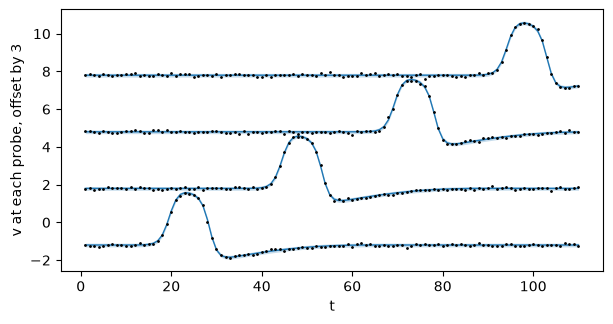

95.5% of the data lie inside the 95% band


In [9]:
band = ds.inference.predict(est, fit, kind="predictive")["v"]
fig, ax = plt.subplots(figsize=(7, 3.4))
for j in range(4):
    off = 3.0 * j
    ax.fill_between(band.times, band.lower[:, j] + off, band.upper[:, j] + off, color="C0", alpha=0.25, lw=0)
    ax.plot(band.times, band.mean[:, j] + off, "C0", lw=1)
    ax.plot(ts, data[:, j] + off, "k.", ms=2)
ax.set_xlabel("t")
ax.set_ylabel("v at each probe, offset by 3")
plt.show()
inside = (data >= band.lower) & (data <= band.upper)
print(f"{inside.mean():.1%} of the data lie inside the 95% band")

The band is the 95 percent predictive interval, mostly measurement noise, and 95.5 percent of the data lie inside it.

## Identifiability

The standard errors are small, but they hide how the parameters move together. `ds.inference.identifiability` reports the eigenvalues of the information matrix at the fit and the parameter correlations, leaving out the prior so that it cannot hide a direction the data leave open.

In [10]:
ident = ds.inference.identifiability(est, fit)
print("eigenvalues     ", np.array2string(np.asarray(ident.raw.eigenvalues), precision=2))
print(f"condition number {ident.raw.condition_number:.2e}")
print("correlation\n", np.array2string(np.asarray(ident.raw.correlation), precision=3))

eigenvalues      [2.18e+08 4.60e+06 3.87e+03]
condition number 5.65e+04
correlation
 [[ 1.    -0.999 -0.876]
 [-0.999  1.     0.852]
 [-0.876  0.852  1.   ]]


The eigenvalues span almost five decades, with a condition number of $5.65 \times 10^4$. The parameters $a$ and $b$ have a correlation of $-0.999$, so the data pin a combination of the two far better than either alone. A fit with $b$ held fixed would therefore understate the error on $a$.